In [ ]:
from pathlib import Path
import os, sys
_root = next((p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if (p / "REPOSITORY_PROVENANCE.json").is_file()), None)
if _root is None:
    raise RuntimeError("Start Jupyter inside this experiment repository.")
os.chdir(_root)
sys.path.insert(0, str(_root))


# Genuine finite-shot training for graph-IQP CartPole policies

This notebook is a **new**, self-contained finite-sampling companion to
`test_policy_training_efficiency.ipynb`. It preserves the current paper setup:

- `CartPole-v1/200`, meaning `CartPole-v1` with 500 training episodes and an
  explicit hard 200-step episode cap;
- the same state scaling and clipping, trainable `NeuralEmbedding`, graph-IQP
  gates, selected depths, initializers, matched seeds, and readout definitions;
- episode-batched REINFORCE (`gamma=0.99`, five episodes/update), normalized
  returns, EMA baseline, entropy coefficient `0.005`, gradient clipping at 1,
  and Adam with AMSGrad at a **constant** learning rate of `0.03` (no scheduler);
- the existing optimization-freeze rule: at a five-episode boundary, freeze
  policy updates once the mean of the most recent up-to-100 returns reaches 195,
  but continue interaction through episode 500.

Finite-shot interaction uses actual measurement frequencies. For two actions,
zero counts are prevented by the symmetric Jeffreys rule

\[
\widetilde p_a=\frac{N_a+1/2}{S+|\mathcal A|/2}
                 =\frac{N_a+1/2}{S+1}.
\]

The same smoothed probabilities are used for behavior sampling, log
probabilities, and entropy. No exact-statevector gradient is mixed with a noisy
forward pass.

## Preregistered reduced design

The source notebook's strongest five-qubit conclusion occurs at depth `L=3`;
the strongest and cheapest ten-qubit cubic-expander conclusion occurs at
`L=1`. Native finite-shot parameter-shift is correct in this stack, but the
pilot below shows that it needs 91 circuit executions per visited state for the
5-qubit `L=3` model and 71 for the 10-qubit `L=1` model. Full
depth-by-shot-by-seed coverage would therefore require several days.

The confirmatory study fixes those two depths in advance and compares exact
analytic gradients, an exact-probability SPSA control, 1,024-shot SPSA, and
4,096-shot SPSA using the first five existing matched seeds for each
architecture. The exact-SPSA control separates the estimator change from shot
noise. The 256-shot condition is retained in the pilot as
a stress test but omitted from the full 500-episode matrix to keep the clean
execution feasible. This reduction changes neither the environment nor the
episode/step caps.

For the confirmatory finite-shot runs, gradients use a documented two-sided
SPSA estimator of the *same REINFORCE loss*. Two Rademacher directions are
averaged per update:

\[
\widehat g_k=\frac1K\sum_{j=1}^{K}
\frac{\widehat L(\theta+c_k\Delta_j)-
      \widehat L(\theta-c_k\Delta_j)}{2c_k}\,\Delta_j,
\qquad K=2,
\]

with independent finite-shot circuit evaluations,
`c_k = 0.1/(k+1)^0.101`, and `Delta_j` containing independent `+1/-1`
entries. This is a standard simultaneous-perturbation stochastic gradient;
unlike post-hoc curve noise, both its rollouts and gradient loss evaluations
consume circuit shots. Because the log is nonlinear, the resulting plug-in
score estimate is consistent but not exactly unbiased at finite `S`; the
Jeffreys rule makes that approximation explicit and symmetric.


In [1]:
import os
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")
os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("MPLCONFIGDIR", "/tmp/qasp-finite-shot-mpl")

import copy
import gc
import hashlib
import json
import math
import platform
import subprocess
import time
from pathlib import Path

import gymnasium as gym
import matplotlib as mpl
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import pennylane as qml
import scipy
import torch
from IPython.display import display

import qasp
from qasp.rl.model import create_model

ROOT = Path.cwd().resolve()
if ROOT.name == "tests":
    ROOT = ROOT.parent
RESULTS_DIR = ROOT / "tests" / "finite_shot_cartpole_results"
FIGURES_DIR = RESULTS_DIR / "figures"
RUNS_DIR = RESULTS_DIR / "runs"
for directory in (RESULTS_DIR, FIGURES_DIR, RUNS_DIR):
    directory.mkdir(parents=True, exist_ok=True)

mpl.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "font.size": 9,
    "axes.titlesize": 10,
    "axes.labelsize": 9,
    "legend.fontsize": 7,
    "lines.linewidth": 1.8,
})

MASTER_SEEDS_5 = (3, 7, 11, 23, 37)
MASTER_SEEDS_10 = (3, 7, 11, 23, 37, 41, 43, 47, 53, 59)
CONFIRMATORY_SEEDS_10 = MASTER_SEEDS_10[:5]
CONDITIONS = (
    {"mode": "exact_analytic", "shots": None, "gradient_estimator": "analytic"},
    {"mode": "exact_spsa", "shots": None, "gradient_estimator": "spsa"},
    {"mode": "shots_1024", "shots": 1024, "gradient_estimator": "spsa"},
    {"mode": "shots_4096", "shots": 4096, "gradient_estimator": "spsa"},
)
PILOT_SHOTS = (256, 1024, 4096)
POLICIES = ("parity", "majority")
N_EPISODES = 500
MAX_STEPS = 200
FINAL_WINDOW = 50
SOLVED_WINDOW = 100
SOLVED_THRESHOLD = 195.0

TRAINING = {
    "gamma": 0.99,
    "lr": 3e-2,
    "lr_schedule": "constant (none)",
    "optimizer": "Adam(amsgrad=True)",
    "batch_episodes": 5,
    "normalize_returns": True,
    "baseline_type": "ema",
    "baseline_momentum": 0.05,
    "entropy_coef": 5e-3,
    "max_grad_norm": 1.0,
    "spsa_directions": 2,
    "spsa_c0": 0.1,
    "spsa_gamma": 0.101,
    "pseudocount_alpha": 0.5,
}

print("PennyLane", qml.__version__, "| PyTorch", torch.__version__)
print("QASP root:", ROOT)
print("Results:", RESULTS_DIR)
print("Confirmatory conditions:", CONDITIONS)
print("5q seeds:", MASTER_SEEDS_5)
print("10q seeds used:", CONFIRMATORY_SEEDS_10,
      "(reduced from", MASTER_SEEDS_10, "after timing pilot)")


PennyLane 0.42.2 | PyTorch 2.7.0
QASP root: .
Results: ./tests/finite_shot_cartpole_results
Confirmatory conditions: ({'mode': 'exact_analytic', 'shots': None, 'gradient_estimator': 'analytic'}, {'mode': 'exact_spsa', 'shots': None, 'gradient_estimator': 'spsa'}, {'mode': 'shots_1024', 'shots': 1024, 'gradient_estimator': 'spsa'}, {'mode': 'shots_4096', 'shots': 4096, 'gradient_estimator': 'spsa'})
5q seeds: (3, 7, 11, 23, 37)
10q seeds used: (3, 7, 11, 23, 37) (reduced from (3, 7, 11, 23, 37, 41, 43, 47, 53, 59) after timing pilot)


In [2]:
EXPANDER_EDGES = [
    (0, 5), (0, 6), (0, 7), (1, 2), (1, 4),
    (1, 7), (2, 6), (2, 8), (3, 4), (3, 7),
    (3, 9), (4, 9), (5, 6), (5, 8), (8, 9),
]

ARCHITECTURES = {
    "ring_5_L3": {
        "label": "5-qubit ring, L=3",
        "n_qubits": 5,
        "n_layers": 3,
        "edges": [(i, (i + 1) % 5) for i in range(5)],
        "measurement_wires": list(range(5)),
        "initializer": "normal_0_1",
        "seeds": MASTER_SEEDS_5,
        "source_depth_reason": "largest majority advantage among the 5q depth sweep",
    },
    "expander_10_L1": {
        "label": "10-qubit cubic expander, L=1",
        "n_qubits": 10,
        "n_layers": 1,
        "edges": EXPANDER_EDGES,
        "measurement_wires": list(range(9)),
        "initializer": "uniform",
        "seeds": CONFIRMATORY_SEEDS_10,
        "source_depth_reason": "largest/cheapest 10q majority contrast in the source sweep",
    },
}

g = nx.Graph()
g.add_nodes_from(range(10))
g.add_edges_from(EXPANDER_EDGES)
adj = nx.to_numpy_array(g, nodelist=range(10))
eig = np.linalg.eigvalsh(adj)
assert nx.is_connected(g) and all(d == 3 for _, d in g.degree())
print("10q connected 3-regular graph:", nx.is_connected(g))
print("Edges:", EXPANDER_EDGES)
print(f"Adjacency spectral gap: {eig[-1] - eig[-2]:.6f}")


def qasp_initial_state(spec, seed):
    '''Use the current QASP factory/initializer as the parameter source.'''
    n = spec["n_qubits"]
    config = {
        "ansatz": "IQPAnsatz",
        "ansatz_config": {
            "n_layers": spec["n_layers"],
            "imprimitive_pattern": copy.deepcopy(spec["edges"]),
            "reuploading": True,
            "include_single_qubit": True,
        },
        "feature_map": "NeuralEmbedding",
        "feature_map_config": {"features": 4, "rotations": "Z"},
        "n_actions": 2,
        "init": spec["initializer"],
        "device": "lightning.qubit",
        "diff_method": "adjoint",
        "shots": None,
        "softmax_activation": False,
        "output_scaling": None,
        "torchrl": False,
        "measurement_qubits": list(spec["measurement_wires"]),
        "parity_cnot_decomposition": False,
        "policy": "parity-like",
        "training_method": "expectation",
        "enable_mpi": False,
    }
    torch.manual_seed(seed)
    np.random.seed(seed)
    model = create_model("PQCBorn", config, n_qubits=n)
    state = {
        key: value.detach().cpu().clone()
        for key, value in model.qlayer.state_dict().items()
    }
    del model
    return state


initialization_audit = []
for architecture, spec in ARCHITECTURES.items():
    for seed in spec["seeds"]:
        state = qasp_initial_state(spec, seed)
        initialization_audit.append({
            "architecture": architecture,
            "seed": seed,
            "scaling_entries": state["input_scaling_params"].numel(),
            "circuit_entries": state["params"].numel(),
            "sha256": hashlib.sha256(
                torch.cat([state["input_scaling_params"].flatten(),
                           state["params"].flatten()]).numpy().tobytes()
            ).hexdigest(),
        })
display(pd.DataFrame(initialization_audit))


10q connected 3-regular graph: True
Edges: [(0, 5), (0, 6), (0, 7), (1, 2), (1, 4), (1, 7), (2, 6), (2, 8), (3, 4), (3, 7), (3, 9), (4, 9), (5, 6), (5, 8), (8, 9)]
Adjacency spectral gap: 0.853351


,architecture,seed,scaling_entries,circuit_entries,sha256
0,ring_5_L3,3,60,30,a326ed08bfff4dc7643fe447ff3b5b67c44b528cb1a6e6...
1,ring_5_L3,7,60,30,0db2dd61fc7d3f4c95b488e0f1f9ca3de6bfb57b39a6b2...
2,ring_5_L3,11,60,30,da7239c9402ae42360b17434601d0dd35f6e72df0b4311...
3,ring_5_L3,23,60,30,4dd123cc96e4dd727cbc6932acbc6b4660182e968e7093...
4,ring_5_L3,37,60,30,8add39ff97ece267681c8bac97778c7a1b5a5da7a2bb85...
5,expander_10_L1,3,40,25,a69b2c88f656d2fcc395c1b2a372c2d663500d5791cab9...
6,expander_10_L1,7,40,25,84859fac6324644e3b0c34684ba49bbd39e26e1d3ed9b2...
7,expander_10_L1,11,40,25,387d121a107f2186245646ac5f6027b0b47dba13f646da...
8,expander_10_L1,23,40,25,ef156006850c5d3140e57bb52ad1d0a2fe7aa6fe9d7258...
9,expander_10_L1,37,40,25,9e4e2240f0020dc0064cb51e4c3a264f7080d371ba69b4...


## QASP-equivalent batched execution backend

The source `NeuralEmbedding` sums over every tensor dimension, so it accepts
single states but cannot broadcast a state batch. Training with native
parameter-shift therefore differentiates every visited state separately. The
backend below writes the same QASP gates explicitly, changing only the tensor
axis handling (`sum(-1)`) so that exact loss reevaluation and SPSA's two
perturbed losses can process a batch efficiently.

The validation cell compares this backend against QASP's current exact parity
and sparse-majority models before any training. Parameter initialization still
comes directly from QASP, and the notebook asserts identical initial tensors
for every policy and shot condition within a seed.


In [3]:
def action_index_for(policy, n_measured):
    states = np.arange(1 << n_measured, dtype=np.int64)
    shifts = np.arange(n_measured - 1, -1, -1, dtype=np.int64)
    bits = (states[:, None] >> shifts[None, :]) & 1
    if policy == "parity":
        return bits.sum(axis=1) % 2
    if policy == "majority":
        return (bits.sum(axis=1) > (n_measured // 2)).astype(np.int64)
    raise ValueError(policy)


def graph_iqp_qfunc(spec):
    n = spec["n_qubits"]
    layers = spec["n_layers"]
    edges = tuple(tuple(edge) for edge in spec["edges"])
    measured = tuple(spec["measurement_wires"])
    block = n + len(edges)

    def circuit(inputs, input_scaling_params, params):
        for wire in range(n):
            qml.Hadamard(wires=wire)
        weights = input_scaling_params.reshape(layers, n, 4)

        def encode(layer):
            if inputs.ndim == 1:
                angles = (weights[layer] * inputs[None, :]).sum(-1)
            else:
                angles = (
                    inputs[:, None, :] * weights[layer][None, :, :]
                ).sum(-1)
            for wire in range(n):
                qml.PauliRot(angles[..., wire], "Z", wires=wire)

        encode(0)
        for layer in range(layers):
            start = layer * block
            for wire in range(n):
                qml.RZ(params[start + wire], wires=wire)
            for offset, (left, right) in enumerate(edges):
                qml.PauliRot(
                    params[start + n + offset], "ZZ", wires=[left, right]
                )
            for wire in range(n):
                qml.Hadamard(wires=wire)
            if layer < layers - 1:
                encode(layer + 1)
        return qml.probs(wires=measured)

    return circuit


def aggregate_torch(basis_probs, action_index):
    index = torch.as_tensor(action_index, dtype=torch.long, device=basis_probs.device)
    flat = basis_probs.reshape(-1, basis_probs.shape[-1])
    result = basis_probs.new_zeros((flat.shape[0], 2))
    result.scatter_add_(1, index[None, :].expand(flat.shape[0], -1), flat)
    return result.reshape(*basis_probs.shape[:-1], 2)


def aggregate_numpy(basis_probs, action_index):
    basis_probs = np.asarray(basis_probs)
    return np.stack(
        [basis_probs[..., action_index == action].sum(axis=-1) for action in range(2)],
        axis=-1,
    )


class IQPExperimentPolicy(torch.nn.Module):
    '''QASP-equivalent Torch statevector with genuine multinomial measurements.'''

    def __init__(self, spec, policy, initial_state, shots, shot_seed):
        super().__init__()
        self.spec = copy.deepcopy(spec)
        self.policy = policy
        self.shots = shots
        self.alpha = TRAINING["pseudocount_alpha"]
        self.input_scaling_params = torch.nn.Parameter(
            initial_state["input_scaling_params"].clone()
        )
        self.params = torch.nn.Parameter(initial_state["params"].clone())
        self.action_index = action_index_for(
            policy, len(spec["measurement_wires"])
        )
        self.shot_rng = np.random.default_rng(int(shot_seed))
        n = spec["n_qubits"]
        dimension = 1 << n
        basis = torch.arange(dimension, dtype=torch.long)
        shifts = torch.arange(n - 1, -1, -1, dtype=torch.long)
        bits = ((basis[:, None] >> shifts[None, :]) & 1).to(torch.float32)
        self.register_buffer("z_signs", (1.0 - 2.0 * bits).T)
        zz = torch.stack(
            [self.z_signs[left] * self.z_signs[right] for left, right in spec["edges"]]
        )
        self.register_buffer("zz_signs", zz)
        measured = list(spec["measurement_wires"])
        measured_index = torch.zeros(dimension, dtype=torch.long)
        for wire in measured:
            measured_index = (measured_index << 1) | bits[:, wire].to(torch.long)
        self.register_buffer("measured_index", measured_index)

    @staticmethod
    def _hadamards(state):
        result = state
        width = 1
        dimension = state.shape[-1]
        while width < dimension:
            blocks = result.reshape(*result.shape[:-1], -1, 2, width)
            left = blocks[..., 0, :]
            right = blocks[..., 1, :]
            result = torch.stack((left + right, left - right), dim=-2)
            result = result.reshape(*state.shape[:-1], dimension) / math.sqrt(2.0)
            width *= 2
        return result

    def exact_basis_probs(self, states, scaling=None, params=None):
        states = torch.as_tensor(states, dtype=torch.float32)
        scaling = self.input_scaling_params if scaling is None else scaling
        params = self.params if params is None else params
        n = self.spec["n_qubits"]
        layers = self.spec["n_layers"]
        edges = self.spec["edges"]
        block = n + len(edges)
        weights = scaling.reshape(layers, n, 4)
        batch_shape = states.shape[:-1]
        dimension = 1 << n
        state = torch.ones(*batch_shape, dimension, dtype=torch.complex64)
        state = state / math.sqrt(dimension)

        def encoding_angles(layer):
            return torch.einsum("...f,qf->...q", states, weights[layer])

        for layer in range(layers):
            encoded = encoding_angles(layer)
            start = layer * block
            phase = params[start : start + n]
            entangling = params[start + n : start + block]
            diagonal_angle = torch.einsum("...q,qd->...d", encoded, self.z_signs)
            diagonal_angle = diagonal_angle + torch.einsum("q,qd->d", phase, self.z_signs)
            diagonal_angle = diagonal_angle + torch.einsum(
                "e,ed->d", entangling, self.zz_signs
            )
            state = state * torch.exp(-0.5j * diagonal_angle)
            state = self._hadamards(state)

        full_probabilities = state.abs().square().real
        measured_dimension = 1 << len(self.spec["measurement_wires"])
        flat = full_probabilities.reshape(-1, dimension)
        measured_probabilities = full_probabilities.new_zeros(
            (flat.shape[0], measured_dimension)
        )
        measured_probabilities.scatter_add_(
            1, self.measured_index[None, :].expand(flat.shape[0], -1), flat
        )
        return measured_probabilities.reshape(*batch_shape, measured_dimension)

    def exact_action_probs(self, states):
        return aggregate_torch(self.exact_basis_probs(states), self.action_index)

    def action_probs_numpy(self, states, flat_parameters=None):
        if flat_parameters is None:
            scaling = self.input_scaling_params.detach().cpu().numpy()
            params = self.params.detach().cpu().numpy()
        else:
            n_scaling = self.input_scaling_params.numel()
            scaling = np.asarray(flat_parameters[:n_scaling], dtype=np.float64)
            params = np.asarray(flat_parameters[n_scaling:], dtype=np.float64)
        with torch.no_grad():
            basis = self.exact_basis_probs(
                torch.as_tensor(states, dtype=torch.float32),
                torch.as_tensor(scaling, dtype=torch.float32),
                torch.as_tensor(params, dtype=torch.float32),
            ).cpu().numpy()
        if self.shots is None:
            return aggregate_numpy(basis, self.action_index)
        flat_basis = basis.reshape(-1, basis.shape[-1])
        def sampled_counts(row):
            probabilities = np.clip(row.astype(np.float64), 0.0, None)
            probabilities /= probabilities.sum()
            prefix = probabilities[:-1].sum()
            if prefix >= 1.0:
                probabilities[:-1] *= np.nextafter(1.0, 0.0) / prefix
            probabilities[-1] = 1.0 - probabilities[:-1].sum()
            return self.shot_rng.multinomial(int(self.shots), probabilities)

        counts = np.stack([
            sampled_counts(row) for row in flat_basis
        ]).reshape(*basis.shape)
        action = aggregate_numpy(counts / self.shots, self.action_index)
        return (self.shots * action + self.alpha) / (
            self.shots + 2 * self.alpha
        )

    def flat_parameters_numpy(self):
        return np.concatenate([
            self.input_scaling_params.detach().cpu().numpy().reshape(-1),
            self.params.detach().cpu().numpy().reshape(-1),
        ]).astype(np.float64, copy=True)

    def assign_flat_gradient(self, gradient):
        gradient = np.asarray(gradient, dtype=np.float32)
        split = self.input_scaling_params.numel()
        self.input_scaling_params.grad = torch.as_tensor(
            gradient[:split].reshape(self.input_scaling_params.shape)
        )
        self.params.grad = torch.as_tensor(
            gradient[split:].reshape(self.params.shape)
        )


def make_qasp_exact_model(spec, policy, seed):
    n = spec["n_qubits"]
    common = {
        "ansatz": "IQPAnsatz",
        "ansatz_config": {
            "n_layers": spec["n_layers"],
            "imprimitive_pattern": copy.deepcopy(spec["edges"]),
            "reuploading": True,
            "include_single_qubit": True,
        },
        "feature_map": "NeuralEmbedding",
        "feature_map_config": {"features": 4, "rotations": "Z"},
        "n_actions": 2,
        "init": spec["initializer"],
        "device": "lightning.qubit",
        "diff_method": "adjoint",
        "shots": None,
        "softmax_activation": False,
        "output_scaling": None,
        "torchrl": False,
        "measurement_qubits": list(spec["measurement_wires"]),
        "parity_cnot_decomposition": False,
        "enable_mpi": False,
    }
    if policy == "parity":
        config = {**common, "policy": "parity-like", "training_method": "expectation"}
    else:
        config = {
            **common,
            "policy": "majority-modulo",
            "training_method": "sparse_projectors",
            "majority_blocks": [list(spec["measurement_wires"])],
        }
    torch.manual_seed(seed)
    np.random.seed(seed)
    return create_model("PQCBorn", config, n_qubits=n)


validation_rows = []
for architecture, spec in ARCHITECTURES.items():
    seed = spec["seeds"][0]
    state = qasp_initial_state(spec, seed)
    x = torch.tensor([0.2, -0.1, 0.05, 0.3], dtype=torch.float32)
    for policy_name in POLICIES:
        reference = make_qasp_exact_model(spec, policy_name, seed)
        reference.qlayer.load_state_dict(state)
        candidate = IQPExperimentPolicy(
            spec, policy_name, state, shots=None, shot_seed=0
        )
        with torch.no_grad():
            expected = reference(x).detach().cpu()
            actual = candidate.exact_action_probs(x).detach().cpu()
        max_error = float(torch.max(torch.abs(expected - actual)))
        torch.testing.assert_close(
            actual, expected, atol=2e-6, rtol=2e-6, check_dtype=False
        )
        validation_rows.append({
            "architecture": architecture,
            "policy": policy_name,
            "QASP probabilities": expected.numpy().tolist(),
            "batched backend probabilities": actual.numpy().tolist(),
            "max_abs_error": max_error,
        })
        del reference, candidate
display(pd.DataFrame(validation_rows))


,architecture,policy,QASP probabilities,batched backend probabilities,max_abs_error
0,ring_5_L3,parity,"[0.5716392397880554, 0.4283607602119446]","[0.571638822555542, 0.42836058139801025]",4.172325e-07
1,ring_5_L3,majority,"[0.7760335206985474, 0.22396647930145264]","[0.7760330438613892, 0.2239663153886795]",4.768372e-07
2,expander_10_L1,parity,"[0.5006393194198608, 0.49936068058013916]","[0.5006393194198608, 0.4993605315685272]",1.490116e-07
3,expander_10_L1,majority,"[0.5361870527267456, 0.4638129472732544]","[0.5361868739128113, 0.4638129472732544]",1.788139e-07


In [4]:
def preprocess_cartpole(state):
    scale = torch.tensor([2.4, 3.0, 0.2095, 3.5], dtype=torch.float32)
    return torch.clamp(torch.as_tensor(state, dtype=torch.float32) / scale, -3.0, 3.0)


def discounted_returns(rewards, gamma=0.99):
    value = 0.0
    result = []
    for reward in reversed(rewards):
        value = float(reward) + gamma * value
        result.insert(0, value)
    return torch.tensor(result, dtype=torch.float32)


def strict_solved_episode(returns, window=100, threshold=195.0):
    values = np.asarray(returns, dtype=float)
    if len(values) < window:
        return np.nan
    rolling = np.convolve(values, np.ones(window) / window, mode="valid")
    hits = np.flatnonzero(rolling >= threshold)
    return float(hits[0] + window) if len(hits) else np.nan


class MatchedFiniteShotREINFORCE:
    '''Same CartPole REINFORCE objective, with exact backprop or finite-shot SPSA.'''

    def __init__(self, policy, seed, gradient_estimator):
        self.policy = policy
        self.seed = int(seed)
        self.gradient_estimator = gradient_estimator
        if gradient_estimator not in {"analytic", "spsa"}:
            raise ValueError(gradient_estimator)
        if gradient_estimator == "analytic" and policy.shots is not None:
            raise ValueError("Finite-shot runs must not use analytic gradients")
        self.optimizer = torch.optim.Adam(
            self.policy.parameters(), lr=TRAINING["lr"], amsgrad=True
        )
        self.baseline = 0.0
        self.baseline_initialized = False
        condition = 0 if policy.shots is None else int(policy.shots)
        self.spsa_rng = np.random.default_rng(7_000_003 + seed + condition)
        self.optimizer_updates = 0
        self.optimized_transitions = 0
        self.interaction_evaluations = 0
        self.gradient_evaluations = 0
        self.optimizer_stop_episode = np.nan

    def update_baseline(self, target):
        if not self.baseline_initialized:
            self.baseline = float(target)
            self.baseline_initialized = True
        else:
            m = TRAINING["baseline_momentum"]
            self.baseline = (1 - m) * self.baseline + m * float(target)

    @staticmethod
    def loss_numpy(probs, actions, advantages):
        selected = np.clip(probs[np.arange(len(actions)), actions], 1e-15, 1.0)
        entropy = -(probs * np.log(np.clip(probs, 1e-15, 1.0))).sum(axis=1)
        return float(
            -(advantages * np.log(selected)).mean()
            - TRAINING["entropy_coef"] * entropy.mean()
        )

    def optimize_exact(self, states, actions, advantages):
        self.optimizer.zero_grad(set_to_none=True)
        probs = self.policy.exact_action_probs(torch.stack(states))
        action_tensor = torch.as_tensor(actions, dtype=torch.long)
        selected = probs.gather(1, action_tensor[:, None]).squeeze(1).clamp_min(1e-12)
        entropy = -(probs * probs.clamp_min(1e-12).log()).sum(dim=1)
        loss = -(advantages.detach() * selected.log()).mean()
        loss = loss - TRAINING["entropy_coef"] * entropy.mean()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(
            list(self.policy.parameters()), TRAINING["max_grad_norm"]
        )
        self.optimizer.step()
        self.gradient_evaluations += len(states)

    def optimize_spsa(self, states, actions, advantages):
        states_np = torch.stack(states).cpu().numpy()
        actions_np = np.asarray(actions, dtype=np.int64)
        advantages_np = advantages.detach().cpu().numpy().astype(np.float64)
        theta = self.policy.flat_parameters_numpy()
        update = self.optimizer_updates
        c_k = TRAINING["spsa_c0"] / ((update + 1) ** TRAINING["spsa_gamma"])
        estimate = np.zeros_like(theta)
        directions = TRAINING["spsa_directions"]
        for _ in range(directions):
            delta = self.spsa_rng.choice((-1.0, 1.0), size=theta.size)
            plus = self.policy.action_probs_numpy(states_np, theta + c_k * delta)
            minus = self.policy.action_probs_numpy(states_np, theta - c_k * delta)
            loss_plus = self.loss_numpy(plus, actions_np, advantages_np)
            loss_minus = self.loss_numpy(minus, actions_np, advantages_np)
            estimate += ((loss_plus - loss_minus) / (2.0 * c_k)) * delta
        estimate /= directions
        self.optimizer.zero_grad(set_to_none=True)
        self.policy.assign_flat_gradient(estimate)
        torch.nn.utils.clip_grad_norm_(
            list(self.policy.parameters()), TRAINING["max_grad_norm"]
        )
        self.optimizer.step()
        self.gradient_evaluations += 2 * directions * len(states)

    def train(self, num_episodes=N_EPISODES, log_every=100):
        torch.manual_seed(self.seed)
        np.random.seed(self.seed)
        env = gym.make("CartPole-v1")
        env.reset(seed=self.seed)
        env.action_space.seed(self.seed)
        returns = []
        batch_states, batch_actions, batch_advantages = [], [], []
        solved = False
        start = time.perf_counter()

        for episode in range(1, num_episodes + 1):
            state, _ = env.reset()
            states, actions, rewards = [], [], []
            for _ in range(MAX_STEPS):
                processed = preprocess_cartpole(state)
                if self.policy.shots is None:
                    with torch.no_grad():
                        probs = self.policy.exact_action_probs(processed).cpu()
                else:
                    probs = torch.as_tensor(
                        self.policy.action_probs_numpy(processed.numpy()),
                        dtype=torch.float32,
                    )
                self.interaction_evaluations += 1
                action = int(torch.distributions.Categorical(probs=probs).sample())
                next_state, reward, terminated, truncated, _ = env.step(action)
                states.append(processed)
                actions.append(action)
                rewards.append(float(reward))
                state = next_state
                if terminated or truncated:
                    break

            returns.append(float(sum(rewards)))
            disc = discounted_returns(rewards, TRAINING["gamma"])
            advantage = disc - self.baseline
            self.update_baseline(float(disc.mean()))
            batch_states.extend(states)
            batch_actions.extend(actions)
            batch_advantages.append(advantage)

            if episode % TRAINING["batch_episodes"] == 0:
                advantages = torch.cat(batch_advantages)
                if TRAINING["normalize_returns"] and len(advantages) > 1:
                    advantages = (advantages - advantages.mean()) / (
                        advantages.std() + 1e-8
                    )
                avg100_current_rule = float(np.mean(returns[-100:]))
                if not solved and avg100_current_rule < SOLVED_THRESHOLD:
                    if self.gradient_estimator == "analytic":
                        self.optimize_exact(batch_states, batch_actions, advantages)
                    else:
                        self.optimize_spsa(batch_states, batch_actions, advantages)
                    self.optimizer_updates += 1
                    self.optimized_transitions += len(batch_states)
                elif not solved:
                    solved = True
                    self.optimizer_stop_episode = float(episode)
                batch_states, batch_actions, batch_advantages = [], [], []

            if episode % log_every == 0:
                print(
                    f"episode={episode:03d} last20={np.mean(returns[-20:]):6.2f} "
                    f"updates={self.optimizer_updates:3d} solved_freeze={solved}",
                    flush=True,
                )

        env.close()
        elapsed = time.perf_counter() - start
        evaluations = self.interaction_evaluations + self.gradient_evaluations
        total_shots = 0 if self.policy.shots is None else int(self.policy.shots * evaluations)
        metadata = {
            "seconds": elapsed,
            "optimizer_updates": self.optimizer_updates,
            "optimized_transitions": self.optimized_transitions,
            "interaction_evaluations": self.interaction_evaluations,
            "gradient_evaluations": self.gradient_evaluations,
            "total_circuit_evaluations": evaluations,
            "total_circuit_shots": total_shots,
            "optimizer_stop_episode": self.optimizer_stop_episode,
            "strict_solved_episode": strict_solved_episode(returns),
        }
        return np.asarray(returns, dtype=float), metadata


## Timing pilot and estimator choice

The pilot has two roles:

1. verify that PennyLane's installed finite-shot parameter-shift path really
   returns sampled probabilities and gradients; and
2. measure its circuit-execution multiplier at the two preregistered depths.

The reported tracker counts include the unshifted forward circuit. We also time
one SPSA-style batched perturbed loss pair. The pilot uses 256, 1,024 and 4,096
shots, but no pilot result is included in the confirmatory statistics.


In [5]:
def make_native_parameter_shift_model(spec, policy_name, seed, shots):
    n = spec["n_qubits"]
    common = {
        "ansatz": "IQPAnsatz",
        "ansatz_config": {
            "n_layers": spec["n_layers"],
            "imprimitive_pattern": copy.deepcopy(spec["edges"]),
            "reuploading": True,
            "include_single_qubit": True,
        },
        "feature_map": "NeuralEmbedding",
        "feature_map_config": {"features": 4, "rotations": "Z"},
        "n_actions": 2,
        "init": spec["initializer"],
        "device": "lightning.qubit",
        "diff_method": "parameter-shift",
        "shots": int(shots),
        "softmax_activation": False,
        "output_scaling": None,
        "torchrl": False,
        "measurement_qubits": list(spec["measurement_wires"]),
        "parity_cnot_decomposition": False,
        "policy": "parity-like" if policy_name == "parity" else "majority-modulo",
        "training_method": "probs",
        "enable_mpi": False,
    }
    if policy_name == "majority":
        common["majority_blocks"] = [list(spec["measurement_wires"])]
    torch.manual_seed(seed)
    np.random.seed(seed)
    return create_model("PQCBorn", common, n_qubits=n)


pilot_rows = []
for architecture, spec in ARCHITECTURES.items():
    seed = spec["seeds"][0]
    state = qasp_initial_state(spec, seed)
    for shots in PILOT_SHOTS:
        native = make_native_parameter_shift_model(spec, "majority", seed, shots)
        native.qlayer.load_state_dict(state)
        x = torch.tensor([0.15, -0.2, 0.08, 0.1], dtype=torch.float32)
        start = time.perf_counter()
        with qml.Tracker(native.circuit_builder.device) as tracker:
            raw = native(x)
            smoothed = (shots * raw + 0.5) / (shots + 1.0)
            (-torch.log(smoothed[1])).backward()
        parameter_shift_seconds = time.perf_counter() - start

        finite = IQPExperimentPolicy(
            spec, "majority", state, shots=shots,
            shot_seed=900_000 + seed + shots,
        )
        states = np.tile(x.numpy(), (64, 1))
        theta = finite.flat_parameters_numpy()
        delta = np.where(np.arange(theta.size) % 2, 1.0, -1.0)
        start = time.perf_counter()
        finite.action_probs_numpy(states, theta + 0.1 * delta)
        finite.action_probs_numpy(states, theta - 0.1 * delta)
        spsa_pair_seconds = time.perf_counter() - start

        pilot_rows.append({
            "architecture": architecture,
            "shots": shots,
            "native_parameter_shift_seconds_per_state": parameter_shift_seconds,
            "native_parameter_shift_circuit_executions": int(tracker.totals["executions"]),
            "native_parameter_shift_total_shots": int(tracker.totals.get("shots", shots * tracker.totals["executions"])),
            "batched_spsa_pair_seconds_for_64_states": spsa_pair_seconds,
        })
        del native, finite
        gc.collect()

pilot_df = pd.DataFrame(pilot_rows)
pilot_df.to_csv(RESULTS_DIR / "pilot_results.csv", index=False)
display(pilot_df.round(4))

for architecture in ARCHITECTURES:
    executions = pilot_df.loc[
        (pilot_df.architecture == architecture) & (pilot_df.shots == 1024),
        "native_parameter_shift_circuit_executions",
    ].iloc[0]
    assert executions in (91, 71), (architecture, executions)
print("Estimator decision: full finite-shot study uses K=2 two-sided SPSA.")
print("Full 256-shot coverage omitted; 256 remains a reported pilot stress test.")


,architecture,shots,native_parameter_shift_seconds_per_state,native_parameter_shift_circuit_executions,native_parameter_shift_total_shots,batched_spsa_pair_seconds_for_64_states
0,ring_5_L3,256,0.3068,91,23296,0.0042
1,ring_5_L3,1024,0.3270,91,93184,0.0054
2,ring_5_L3,4096,0.3344,91,372736,0.0057
3,expander_10_L1,256,0.2203,71,18176,0.0197
4,expander_10_L1,1024,0.2350,71,72704,0.0226
5,expander_10_L1,4096,0.2447,71,290816,0.0250


Estimator decision: full finite-shot study uses K=2 two-sided SPSA.
Full 256-shot coverage omitted; 256 remains a reported pilot stress test.


## Confirmatory 500-episode experiment

Each architecture/seed creates one QASP initialization. That tensor is copied
unchanged into every combination of readout and shot budget. The assertions
below verify the hashes before training. Exact runs use differentiable
statevector probabilities; finite runs use empirical frequencies for both
interaction and the two perturbed SPSA losses.

The ten-qubit confirmatory study uses five rather than ten seeds. With two
policies and four estimator/sampling conditions this is already 40 ten-qubit,
500-episode runs. The omitted five seeds and omitted depths are the declared
runtime compromise; neither outcome-based seed selection nor adaptive metric
switching is used.


In [6]:
all_returns = []
run_metadata = []
existing_metadata_path = RESULTS_DIR / "run_metadata.csv"
existing_metadata_df = (
    pd.read_csv(existing_metadata_path)
    if existing_metadata_path.exists()
    else pd.DataFrame()
)

for architecture, spec in ARCHITECTURES.items():
    for seed in spec["seeds"]:
        initial_state = qasp_initial_state(spec, seed)
        expected_hash = hashlib.sha256(
            torch.cat([initial_state["input_scaling_params"].flatten(),
                       initial_state["params"].flatten()]).numpy().tobytes()
        ).hexdigest()
        for condition in CONDITIONS:
            mode = condition["mode"]
            shots = condition["shots"]
            gradient_estimator = condition["gradient_estimator"]
            shot_seed = 1_000_003 + 10_000 * seed + (0 if shots is None else shots)
            for policy_name in POLICIES:
                run_id = f"{architecture}__{policy_name}__{mode}__seed_{seed}"
                checkpoint_path = RUNS_DIR / f"{run_id}.npz"
                previous = (
                    existing_metadata_df[existing_metadata_df.run_id == run_id]
                    if not existing_metadata_df.empty
                    else pd.DataFrame()
                )
                if checkpoint_path.exists() and len(previous) == 1:
                    with np.load(checkpoint_path) as checkpoint:
                        returns = checkpoint["returns"].astype(float)
                    if len(returns) == N_EPISODES:
                        print(f"CHECKPOINT {run_id}", flush=True)
                        for episode, value in enumerate(returns, start=1):
                            all_returns.append({
                                "architecture": architecture,
                                "architecture_label": spec["label"],
                                "n_qubits": spec["n_qubits"],
                                "depth": spec["n_layers"],
                                "policy": policy_name,
                                "mode": mode,
                                "shots_per_evaluation": 0 if shots is None else shots,
                                "seed": seed,
                                "episode": episode,
                                "return": value,
                            })
                        run_metadata.append(previous.iloc[0].to_dict())
                        continue

                policy = IQPExperimentPolicy(
                    spec, policy_name, initial_state, shots, shot_seed
                )
                actual_hash = hashlib.sha256(
                    torch.cat([
                        policy.input_scaling_params.detach().flatten(),
                        policy.params.detach().flatten(),
                    ]).cpu().numpy().tobytes()
                ).hexdigest()
                assert actual_hash == expected_hash

                print(
                    f"\n=== {spec['label']} | {policy_name} | {mode} | seed={seed} ===",
                    flush=True,
                )
                trainer = MatchedFiniteShotREINFORCE(
                    policy, seed, gradient_estimator=gradient_estimator
                )
                returns, metadata = trainer.train()
                final_50 = float(returns[-FINAL_WINDOW:].mean())
                print(
                    f"DONE final50={final_50:.2f} seconds={metadata['seconds']:.1f} "
                    f"evals={metadata['total_circuit_evaluations']:,} "
                    f"shots={metadata['total_circuit_shots']:,}",
                    flush=True,
                )

                np.savez_compressed(
                    RUNS_DIR / f"{run_id}.npz",
                    returns=returns,
                    architecture=architecture,
                    policy=policy_name,
                    mode=mode,
                    shots=-1 if shots is None else shots,
                    seed=seed,
                )
                for episode, value in enumerate(returns, start=1):
                    all_returns.append({
                        "architecture": architecture,
                        "architecture_label": spec["label"],
                        "n_qubits": spec["n_qubits"],
                        "depth": spec["n_layers"],
                        "policy": policy_name,
                        "mode": mode,
                        "shots_per_evaluation": 0 if shots is None else shots,
                        "seed": seed,
                        "episode": episode,
                        "return": value,
                    })
                run_metadata.append({
                    "run_id": run_id,
                    "architecture": architecture,
                    "architecture_label": spec["label"],
                    "n_qubits": spec["n_qubits"],
                    "depth": spec["n_layers"],
                    "policy": policy_name,
                    "mode": mode,
                    "gradient_estimator": gradient_estimator,
                    "shots_per_evaluation": 0 if shots is None else shots,
                    "seed": seed,
                    "initial_parameter_sha256": expected_hash,
                    "final_50": final_50,
                    **metadata,
                })
                del policy, trainer
                gc.collect()

returns_df = pd.DataFrame(all_returns)
run_metadata_df = pd.DataFrame(run_metadata)
returns_df.to_csv(RESULTS_DIR / "episode_returns.csv", index=False)
run_metadata_df.to_csv(RESULTS_DIR / "run_metadata.csv", index=False)
print("Completed runs:", len(run_metadata_df))
display(run_metadata_df.head())


CHECKPOINT ring_5_L3__parity__exact_analytic__seed_3


CHECKPOINT ring_5_L3__majority__exact_analytic__seed_3


CHECKPOINT ring_5_L3__parity__exact_spsa__seed_3


CHECKPOINT ring_5_L3__majority__exact_spsa__seed_3


CHECKPOINT ring_5_L3__parity__shots_1024__seed_3


CHECKPOINT ring_5_L3__majority__shots_1024__seed_3


... (72 outputs left out)

CHECKPOINT expander_10_L1__parity__shots_4096__seed_37


CHECKPOINT expander_10_L1__majority__shots_4096__seed_37


Completed runs: 80


,run_id,architecture,architecture_label,n_qubits,depth,policy,mode,gradient_estimator,shots_per_evaluation,seed,...,final_50,seconds,optimizer_updates,optimized_transitions,interaction_evaluations,gradient_evaluations,total_circuit_evaluations,total_circuit_shots,optimizer_stop_episode,strict_solved_episode
0,ring_5_L3__parity__exact_analytic__seed_3,ring_5_L3,"5-qubit ring, L=3",5,3,parity,exact_analytic,analytic,0,3,...,187.00,44.745783,100,57033,57033,57033,114066,0,NaN,NaN
1,ring_5_L3__majority__exact_analytic__seed_3,ring_5_L3,"5-qubit ring, L=3",5,3,majority,exact_analytic,analytic,0,3,...,199.84,64.380100,71,53307,82225,53307,135532,0,360.0,357.0
2,ring_5_L3__parity__exact_spsa__seed_3,ring_5_L3,"5-qubit ring, L=3",5,3,parity,exact_spsa,spsa,0,3,...,70.56,16.818096,100,21380,21380,85520,106900,0,NaN,NaN
3,ring_5_L3__majority__exact_spsa__seed_3,ring_5_L3,"5-qubit ring, L=3",5,3,majority,exact_spsa,spsa,0,3,...,129.10,27.023620,100,33566,33566,134264,167830,0,NaN,NaN
4,ring_5_L3__parity__shots_1024__seed_3,ring_5_L3,"5-qubit ring, L=3",5,3,parity,shots_1024,spsa,1024,3,...,65.32,17.451199,100,19411,19411,77644,97055,99384320,NaN,NaN


In [7]:
def paired_bootstrap(values_a, values_b, rng, repetitions=20_000):
    a = np.asarray(values_a, dtype=float)
    b = np.asarray(values_b, dtype=float)
    if len(a) != len(b):
        raise ValueError("Paired samples must have equal length")
    if len(a) != 5:
        raise ValueError(f"Expected five matched seeds, received {len(a)}")
    difference = a - b
    indices = rng.integers(0, len(difference), size=(repetitions, len(difference)))
    boot = difference[indices].mean(axis=1)
    mean_difference = float(difference.mean())
    sd_difference = float(difference.std(ddof=1)) if len(difference) > 1 else np.nan
    effect_dz = mean_difference / sd_difference if sd_difference > 0 else np.nan
    return mean_difference, np.quantile(boot, [0.025, 0.975]), effect_dz


summary_rows = []
for keys, group in run_metadata_df.groupby(
    ["architecture", "architecture_label", "n_qubits", "depth", "policy", "mode", "shots_per_evaluation"],
    sort=False,
):
    architecture, label, n_qubits, depth, policy, mode, shots = keys
    final = group["final_50"].to_numpy(float)
    summary_rows.append({
        "architecture": architecture,
        "architecture_label": label,
        "n_qubits": n_qubits,
        "depth": depth,
        "policy": policy,
        "mode": mode,
        "shots_per_evaluation": shots,
        "n_seeds": len(group),
        "mean_final_50": final.mean(),
        "sem_final_50": final.std(ddof=1) / np.sqrt(len(final)),
        "solved_seed_fraction": np.isfinite(group["strict_solved_episode"]).mean(),
        "mean_runtime_seconds": group["seconds"].mean(),
        "total_circuit_evaluations": int(group["total_circuit_evaluations"].sum()),
        "total_circuit_shots": int(group["total_circuit_shots"].sum()),
    })
summary_df = pd.DataFrame(summary_rows)

rng = np.random.default_rng(20260917)
comparison_rows = []

# SPSA/shot conditions minus exact analytic, paired within architecture/policy/seed.
for architecture in ARCHITECTURES:
    for policy_name in POLICIES:
        exact = run_metadata_df[
            (run_metadata_df.architecture == architecture)
            & (run_metadata_df.policy == policy_name)
            & (run_metadata_df["mode"] == "exact_analytic")
        ].sort_values("seed")
        for compared_mode in ("exact_spsa", "shots_1024", "shots_4096"):
            compared = run_metadata_df[
                (run_metadata_df.architecture == architecture)
                & (run_metadata_df.policy == policy_name)
                & (run_metadata_df["mode"] == compared_mode)
            ].sort_values("seed")
            assert exact.seed.tolist() == compared.seed.tolist()
            diff, ci, dz = paired_bootstrap(
                compared.final_50, exact.final_50, rng
            )
            comparison_rows.append({
                "comparison_family": "condition_minus_exact_analytic",
                "architecture": architecture,
                "policy_or_mode": policy_name,
                "contrast": f"{compared_mode} - exact_analytic",
                "n_pairs": len(exact),
                "mean_paired_difference_final_50": diff,
                "ci95_low": ci[0],
                "ci95_high": ci[1],
                "paired_effect_size_dz": dz,
            })

# Finite-shot conditions minus exact-probability SPSA, isolating shot noise from
# the change in gradient estimator.
for architecture in ARCHITECTURES:
    for policy_name in POLICIES:
        exact_spsa = run_metadata_df[
            (run_metadata_df.architecture == architecture)
            & (run_metadata_df.policy == policy_name)
            & (run_metadata_df["mode"] == "exact_spsa")
        ].sort_values("seed")
        for compared_mode in ("shots_1024", "shots_4096"):
            compared = run_metadata_df[
                (run_metadata_df.architecture == architecture)
                & (run_metadata_df.policy == policy_name)
                & (run_metadata_df["mode"] == compared_mode)
            ].sort_values("seed")
            assert exact_spsa.seed.tolist() == compared.seed.tolist()
            diff, ci, dz = paired_bootstrap(
                compared.final_50, exact_spsa.final_50, rng
            )
            comparison_rows.append({
                "comparison_family": "finite_shots_minus_exact_spsa",
                "architecture": architecture,
                "policy_or_mode": policy_name,
                "contrast": f"{compared_mode} - exact_spsa",
                "n_pairs": len(exact_spsa),
                "mean_paired_difference_final_50": diff,
                "ci95_low": ci[0],
                "ci95_high": ci[1],
                "paired_effect_size_dz": dz,
            })

# Majority minus parity, paired within architecture/mode/seed.
for architecture in ARCHITECTURES:
    for mode in ("exact_analytic", "exact_spsa", "shots_1024", "shots_4096"):
        parity = run_metadata_df[
            (run_metadata_df.architecture == architecture)
            & (run_metadata_df.policy == "parity")
            & (run_metadata_df["mode"] == mode)
        ].sort_values("seed")
        majority = run_metadata_df[
            (run_metadata_df.architecture == architecture)
            & (run_metadata_df.policy == "majority")
            & (run_metadata_df["mode"] == mode)
        ].sort_values("seed")
        assert parity.seed.tolist() == majority.seed.tolist()
        diff, ci, dz = paired_bootstrap(
            majority.final_50, parity.final_50, rng
        )
        comparison_rows.append({
            "comparison_family": "majority_minus_parity",
            "architecture": architecture,
            "policy_or_mode": mode,
            "contrast": "majority - parity",
            "n_pairs": len(parity),
            "mean_paired_difference_final_50": diff,
            "ci95_low": ci[0],
            "ci95_high": ci[1],
            "paired_effect_size_dz": dz,
        })

comparisons_df = pd.DataFrame(comparison_rows)
assert len(comparisons_df) == 28
assert comparisons_df["n_pairs"].eq(5).all()
assert comparisons_df[[
    "mean_paired_difference_final_50", "ci95_low", "ci95_high"
]].notna().all().all()
summary_df.to_csv(RESULTS_DIR / "summary_metrics.csv", index=False)
comparisons_df.to_csv(RESULTS_DIR / "paired_comparisons.csv", index=False)
display(summary_df.round(3))
display(comparisons_df.round(3))


,architecture,architecture_label,n_qubits,depth,policy,mode,shots_per_evaluation,n_seeds,mean_final_50,sem_final_50,solved_seed_fraction,mean_runtime_seconds,total_circuit_evaluations,total_circuit_shots
0,ring_5_L3,"5-qubit ring, L=3",5,3,parity,exact_analytic,0,5,173.892,7.462,0.0,46.234,555068,0
1,ring_5_L3,"5-qubit ring, L=3",5,3,majority,exact_analytic,0,5,192.600,4.861,0.6,64.237,687860,0
2,ring_5_L3,"5-qubit ring, L=3",5,3,parity,exact_spsa,0,5,57.400,7.623,0.0,16.317,473900,0
3,ring_5_L3,"5-qubit ring, L=3",5,3,majority,exact_spsa,0,5,73.600,16.690,0.0,21.171,534210,0
4,ring_5_L3,"5-qubit ring, L=3",5,3,parity,shots_1024,1024,5,50.036,7.619,0.0,21.337,426850,437094400
5,ring_5_L3,"5-qubit ring, L=3",5,3,majority,shots_1024,1024,5,78.560,12.260,0.0,25.497,587655,601758720
6,ring_5_L3,"5-qubit ring, L=3",5,3,parity,shots_4096,4096,5,53.356,5.865,0.0,17.509,441280,1807482880
7,ring_5_L3,"5-qubit ring, L=3",5,3,majority,shots_4096,4096,5,74.684,5.990,0.0,20.563,542870,2223595520
8,expander_10_L1,"10-qubit cubic expander, L=1",10,1,parity,exact_analytic,0,5,37.648,4.769,0.0,11.181,143488,0
9,expander_10_L1,"10-qubit cubic expander, L=1",10,1,majority,exact_analytic,0,5,187.172,10.366,0.6,43.173,472814,0


,comparison_family,architecture,policy_or_mode,contrast,n_pairs,mean_paired_difference_final_50,ci95_low,ci95_high,paired_effect_size_dz
0,condition_minus_exact_analytic,ring_5_L3,parity,exact_spsa - exact_analytic,5,-116.492,-130.732,-100.864,-6.348
1,condition_minus_exact_analytic,ring_5_L3,parity,shots_1024 - exact_analytic,5,-123.856,-131.108,-117.336,-14.146
2,condition_minus_exact_analytic,ring_5_L3,parity,shots_4096 - exact_analytic,5,-120.536,-131.076,-109.836,-8.720
3,condition_minus_exact_analytic,ring_5_L3,majority,exact_spsa - exact_analytic,5,-119.000,-150.084,-90.384,-3.079
4,condition_minus_exact_analytic,ring_5_L3,majority,shots_1024 - exact_analytic,5,-114.040,-135.004,-89.072,-4.009
5,condition_minus_exact_analytic,ring_5_L3,majority,shots_4096 - exact_analytic,5,-117.916,-132.216,-108.464,-7.325
6,condition_minus_exact_analytic,expander_10_L1,parity,exact_spsa - exact_analytic,5,-13.540,-21.312,-5.604,-1.333
7,condition_minus_exact_analytic,expander_10_L1,parity,shots_1024 - exact_analytic,5,-15.684,-24.184,-6.084,-1.328
8,condition_minus_exact_analytic,expander_10_L1,parity,shots_4096 - exact_analytic,5,-12.988,-20.316,-4.568,-1.306
9,condition_minus_exact_analytic,expander_10_L1,majority,exact_spsa - exact_analytic,5,-118.464,-140.972,-96.716,-4.219


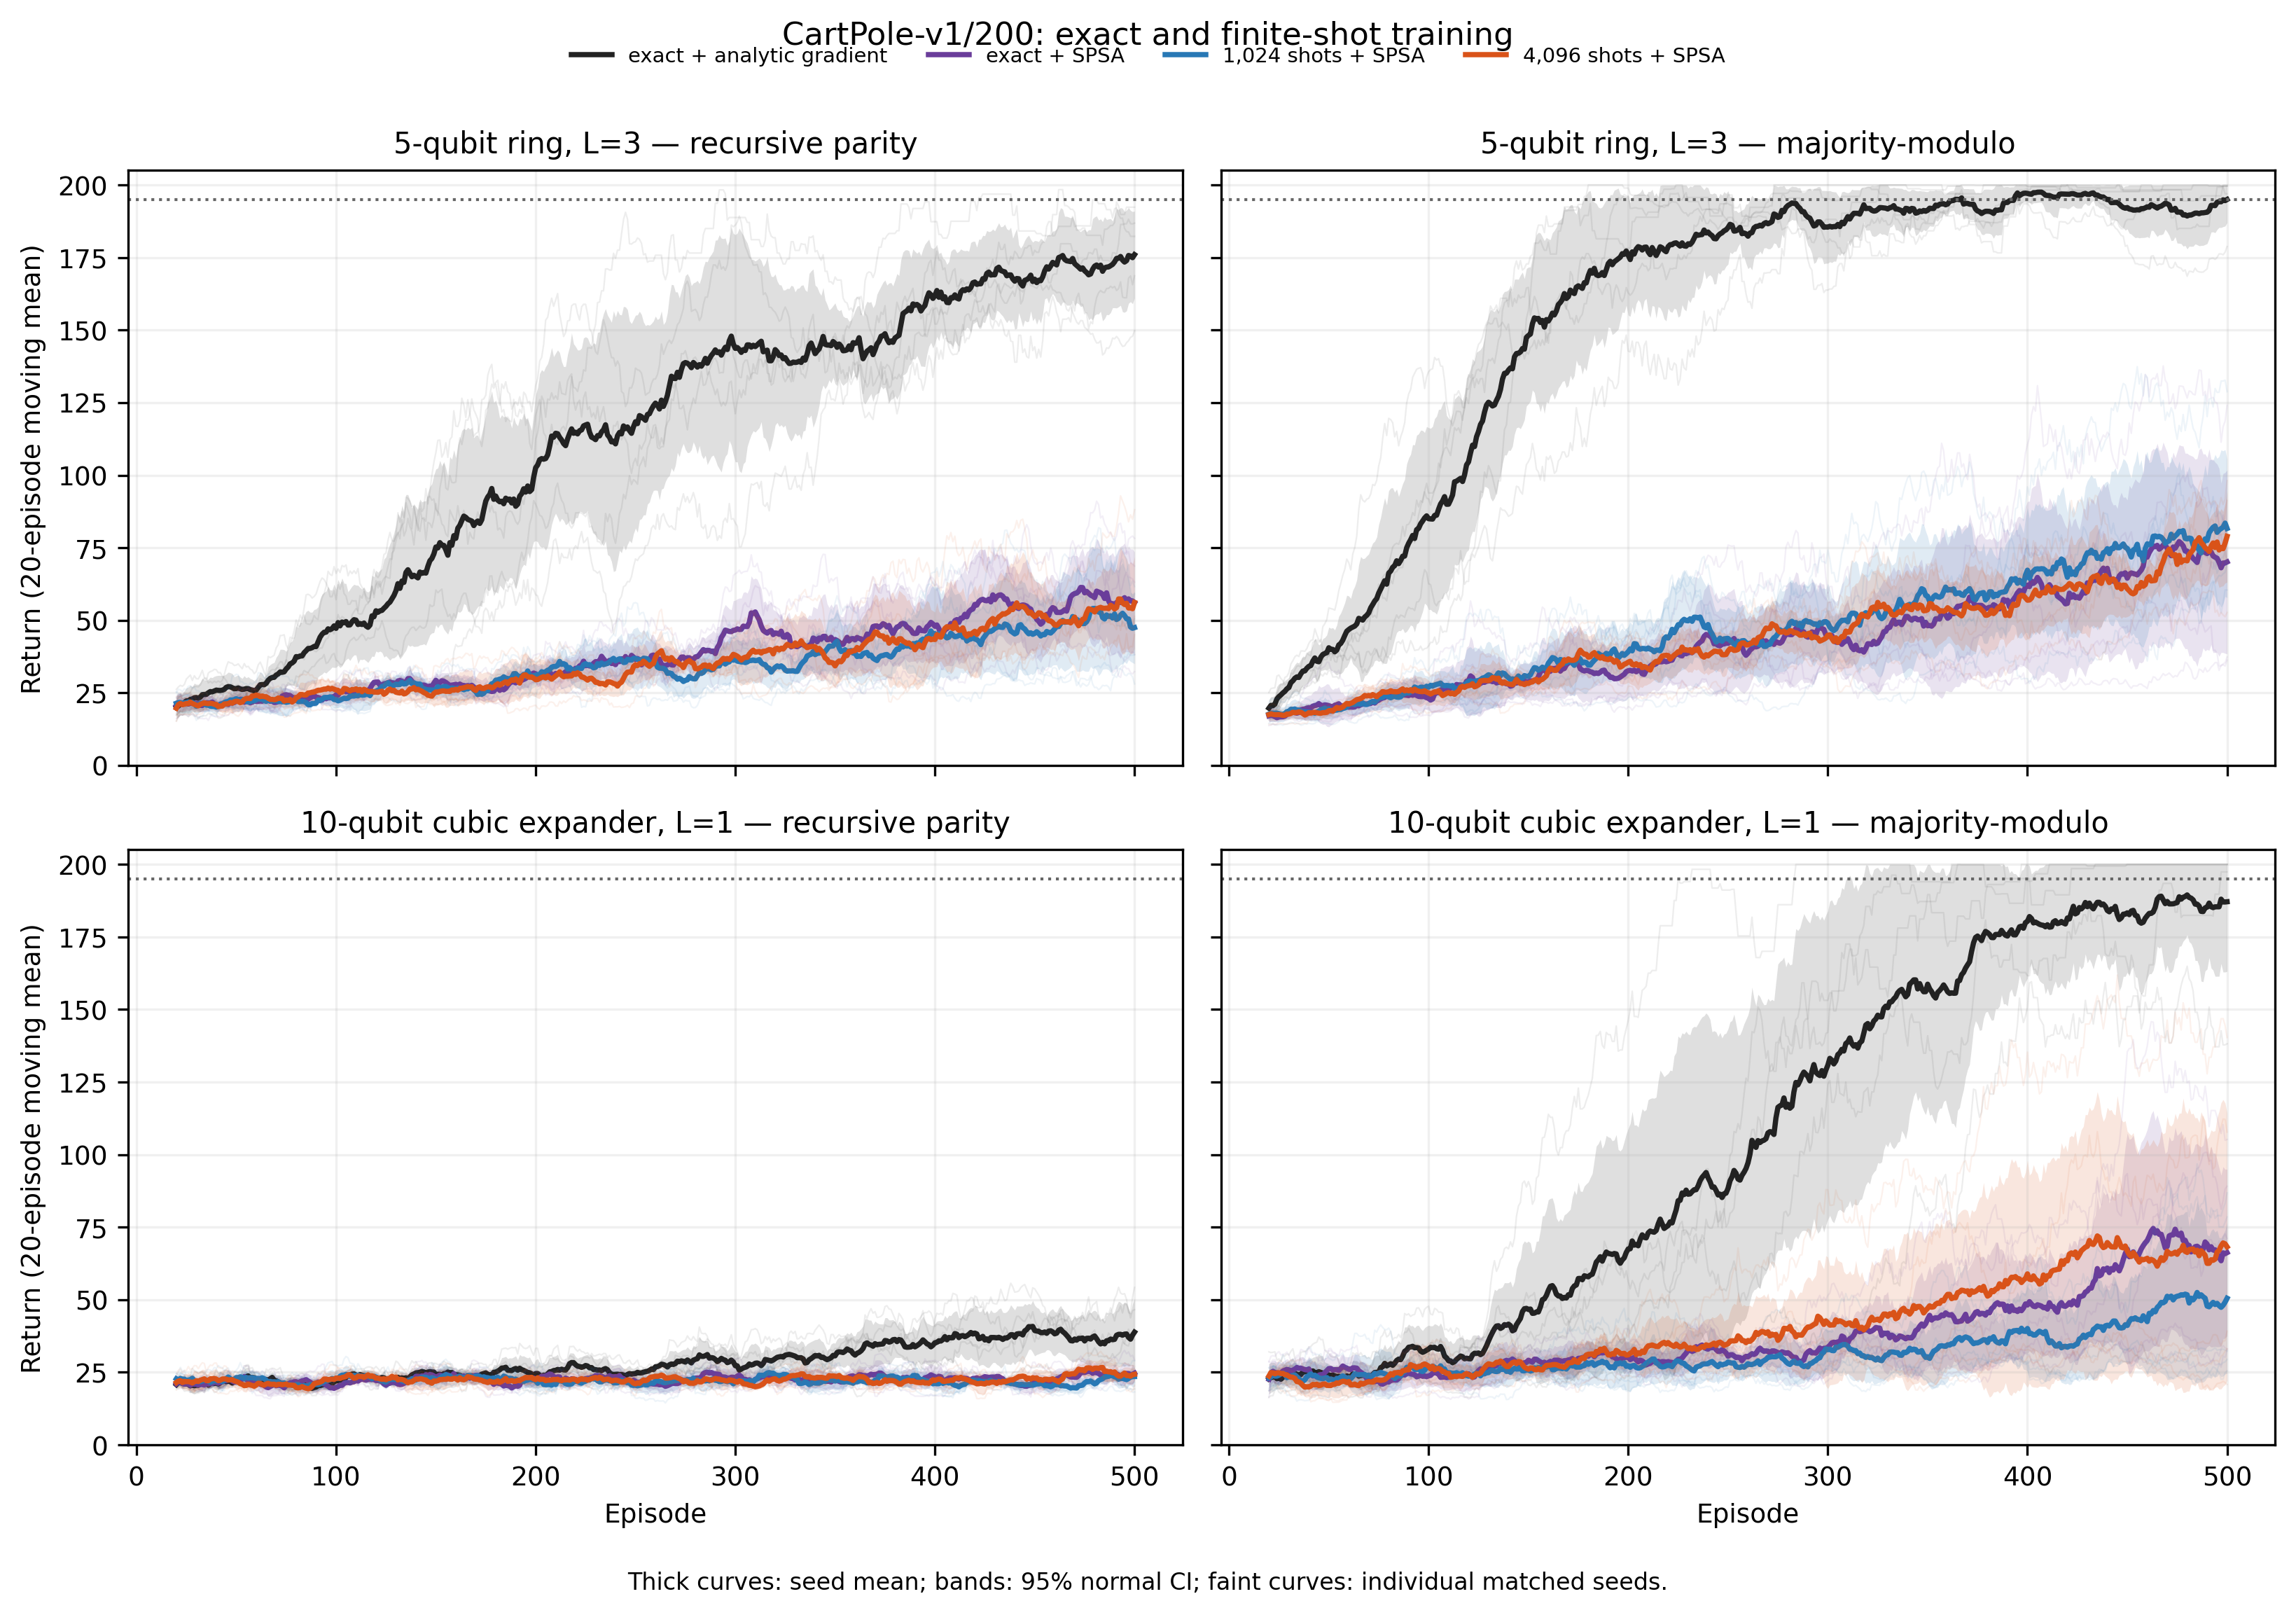

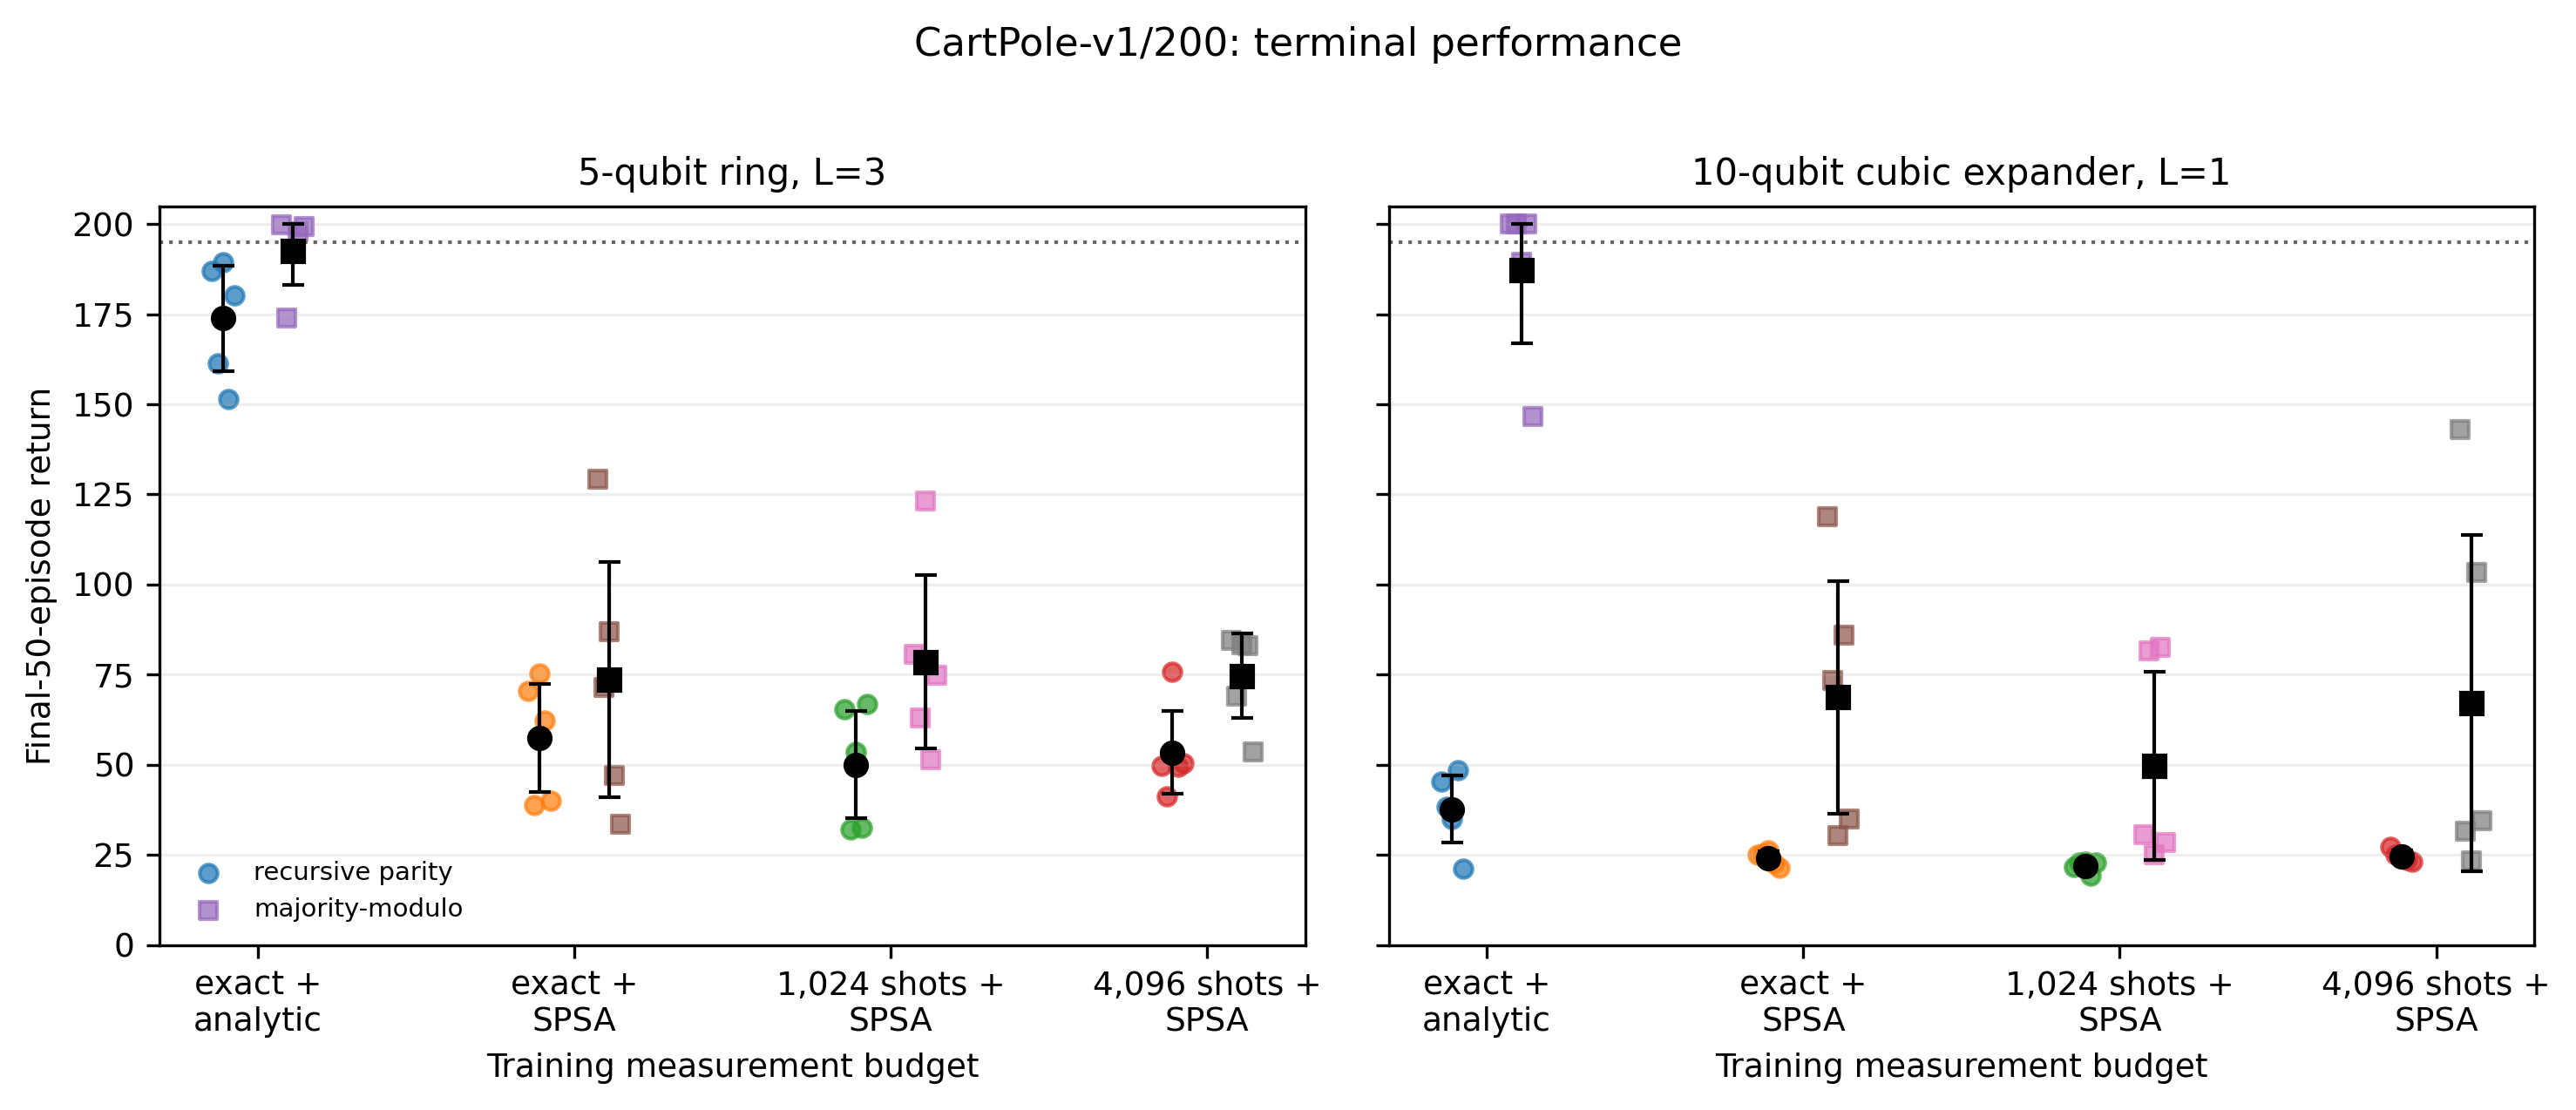

Saved: ./tests/finite_shot_cartpole_results/figures/finite_shot_learning_curves.png
Saved: ./tests/finite_shot_cartpole_results/figures/finite_shot_learning_curves.pdf
Saved: ./tests/finite_shot_cartpole_results/figures/finite_shot_final50_paired.png
Saved: ./tests/finite_shot_cartpole_results/figures/finite_shot_final50_paired.pdf


In [8]:
mode_order = ["exact_analytic", "exact_spsa", "shots_1024", "shots_4096"]
mode_labels = {
    "exact_analytic": "exact + analytic gradient",
    "exact_spsa": "exact + SPSA",
    "shots_1024": "1,024 shots + SPSA",
    "shots_4096": "4,096 shots + SPSA",
}
terminal_mode_labels = {
    "exact_analytic": "exact +\nanalytic",
    "exact_spsa": "exact +\nSPSA",
    "shots_1024": "1,024 shots +\nSPSA",
    "shots_4096": "4,096 shots +\nSPSA",
}
mode_colors = {
    "exact_analytic": "#222222",
    "exact_spsa": "#6A3D9A",
    "shots_1024": "#2878B5",
    "shots_4096": "#D95319",
}
policy_titles = {"parity": "recursive parity", "majority": "majority-modulo"}

fig, axes = plt.subplots(2, 2, figsize=(11.0, 7.2), dpi=300, sharex=True, sharey=True)
for row, (architecture, spec) in enumerate(ARCHITECTURES.items()):
    for col, policy_name in enumerate(POLICIES):
        ax = axes[row, col]
        for mode in mode_order:
            subset = returns_df[
                (returns_df.architecture == architecture)
                & (returns_df.policy == policy_name)
                & (returns_df["mode"] == mode)
            ]
            pivot = subset.pivot(index="seed", columns="episode", values="return").sort_index()
            trajectories = pivot.to_numpy(float)
            window = 20
            smooth = np.stack([
                np.convolve(run, np.ones(window) / window, mode="valid")
                for run in trajectories
            ])
            episodes = np.arange(window, N_EPISODES + 1)
            mean = smooth.mean(axis=0)
            sem = smooth.std(axis=0, ddof=1) / np.sqrt(len(smooth))
            ci = 1.96 * sem
            color = mode_colors[mode]
            for seed_curve in smooth:
                ax.plot(episodes, seed_curve, color=color, alpha=0.08, linewidth=0.55)
            ax.fill_between(
                episodes,
                np.clip(mean - ci, 0, 200),
                np.clip(mean + ci, 0, 200),
                color=color, alpha=0.14, linewidth=0,
            )
            ax.plot(episodes, mean, color=color, label=mode_labels[mode])
        ax.axhline(SOLVED_THRESHOLD, color="#666666", linestyle=":", linewidth=1.0)
        ax.set_title(f"{spec['label']} — {policy_titles[policy_name]}")
        ax.set_ylim(0, 205)
        ax.grid(alpha=0.18)
        if row == 1:
            ax.set_xlabel("Episode")
        if col == 0:
            ax.set_ylabel("Return (20-episode moving mean)")

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=4, frameon=False, bbox_to_anchor=(0.5, 1.01))
fig.suptitle("CartPole-v1/200: exact and finite-shot training", y=1.015)
fig.text(
    0.5, -0.01,
    "Thick curves: seed mean; bands: 95% normal CI; faint curves: individual matched seeds.",
    ha="center", va="top", fontsize=8,
)
fig.tight_layout()
main_png = FIGURES_DIR / "finite_shot_learning_curves.png"
main_pdf = FIGURES_DIR / "finite_shot_learning_curves.pdf"
fig.savefig(main_png, dpi=300, bbox_inches="tight")
fig.savefig(main_pdf, bbox_inches="tight")
plt.show()

# Terminal final-50 paired points.
fig2, axes2 = plt.subplots(1, 2, figsize=(10.0, 4.1), dpi=300, sharey=True)
for ax, (architecture, spec) in zip(axes2, ARCHITECTURES.items()):
    x_positions = np.arange(len(mode_order))
    offsets = {"parity": -0.11, "majority": 0.11}
    markers = {"parity": "o", "majority": "s"}
    for policy_name in POLICIES:
        for x, mode in zip(x_positions, mode_order):
            values = run_metadata_df[
                (run_metadata_df.architecture == architecture)
                & (run_metadata_df.policy == policy_name)
                & (run_metadata_df["mode"] == mode)
            ].sort_values("seed").final_50.to_numpy(float)
            jitter = np.linspace(-0.035, 0.035, len(values))
            ax.scatter(
                np.full(len(values), x + offsets[policy_name]) + jitter,
                values, marker=markers[policy_name], s=24, alpha=0.72,
                label=policy_titles[policy_name] if x == 0 else None,
            )
            point_mean = values.mean()
            half_width = 1.96 * values.std(ddof=1) / np.sqrt(len(values))
            interval_low = np.clip(point_mean - half_width, 0, 200)
            interval_high = np.clip(point_mean + half_width, 0, 200)
            ax.errorbar(
                x + offsets[policy_name], point_mean,
                yerr=np.array([[point_mean - interval_low], [interval_high - point_mean]]),
                color="black", marker=markers[policy_name], capsize=3, linewidth=1,
            )
    ax.axhline(195, color="#666666", linestyle=":", linewidth=1)
    ax.set_xticks(x_positions, [terminal_mode_labels[m] for m in mode_order])
    ax.set_title(spec["label"])
    ax.set_xlabel("Training measurement budget")
    ax.set_ylim(0, 205)
    ax.grid(axis="y", alpha=0.2)
axes2[0].set_ylabel("Final-50-episode return")
axes2[0].legend(frameon=False)
fig2.suptitle("CartPole-v1/200: terminal performance", y=1.02)
fig2.tight_layout()
terminal_png = FIGURES_DIR / "finite_shot_final50_paired.png"
terminal_pdf = FIGURES_DIR / "finite_shot_final50_paired.pdf"
fig2.savefig(terminal_png, dpi=300, bbox_inches="tight")
fig2.savefig(terminal_pdf, bbox_inches="tight")
plt.show()

print("Saved:", main_png)
print("Saved:", main_pdf)
print("Saved:", terminal_png)
print("Saved:", terminal_pdf)


In [9]:
try:
    git_commit = subprocess.check_output(
        ["git", "rev-parse", "HEAD"], cwd=ROOT, text=True
    ).strip()
    git_dirty = bool(subprocess.check_output(
        ["git", "status", "--porcelain"], cwd=ROOT, text=True
    ).strip())
except Exception:
    git_commit, git_dirty = None, None

config_metadata = {
    "created_utc": pd.Timestamp.utcnow().isoformat(),
    "source_notebook": str(ROOT / "tests" / "test_policy_training_efficiency.ipynb"),
    "notebook": str(ROOT / "tests" / "test_policy_training_efficiency_finite_shots.ipynb"),
    "results_directory": str(RESULTS_DIR),
    "environment_label": "CartPole-v1/200",
    "gymnasium_environment_id": "CartPole-v1",
    "architectures": ARCHITECTURES,
    "conditions": CONDITIONS,
    "pilot_shots": list(PILOT_SHOTS),
    "policies": list(POLICIES),
    "episodes": N_EPISODES,
    "max_steps": MAX_STEPS,
    "terminal_metric": f"mean return over final {FINAL_WINDOW} episodes",
    "solved_metric": f"first full {SOLVED_WINDOW}-episode rolling mean >= {SOLVED_THRESHOLD}",
    "optimizer_freeze_rule": "at 5-episode boundary, mean of most recent up-to-100 returns >=195; interaction continues to episode 500",
    "finite_probability_rule": "Jeffreys alpha=0.5 per action: (count+0.5)/(shots+1)",
    "finite_gradient_estimator": "two-sided SPSA, 2 Rademacher directions/update, independent finite-shot losses",
    "training": TRAINING,
    "versions": {
        "python": platform.python_version(),
        "qasp": getattr(qasp, "__version__", "local checkout"),
        "pennylane": qml.__version__,
        "torch": torch.__version__,
        "numpy": np.__version__,
        "pandas": pd.__version__,
        "scipy": scipy.__version__,
        "gymnasium": gym.__version__,
    },
    "git_commit": git_commit,
    "git_dirty": git_dirty,
    "runtime_compromises": [
        "Only source-paper strongest depths: 5q L=3 and 10q L=1.",
        "Five of the ten existing 10q seeds used after timing pilot.",
        "256 shots retained in pilot only; confirmatory finite budgets are 1024 and 4096.",
        "Native finite-shot parameter-shift validated but replaced by explicit SPSA for confirmatory runtime feasibility.",
    ],
}

with open(RESULTS_DIR / "experiment_config.json", "w") as handle:
    json.dump(config_metadata, handle, indent=2, default=str)

manifest_rows = []
for path in sorted(RESULTS_DIR.rglob("*")):
    if path.is_file():
        manifest_rows.append({
            "path": str(path.relative_to(RESULTS_DIR)),
            "bytes": path.stat().st_size,
            "sha256": hashlib.sha256(path.read_bytes()).hexdigest(),
        })
manifest_df = pd.DataFrame(manifest_rows)
manifest_df.to_csv(RESULTS_DIR / "manifest.csv", index=False)

total_runtime = run_metadata_df.seconds.sum()
total_evaluations = int(run_metadata_df.total_circuit_evaluations.sum())
total_shots = int(run_metadata_df.total_circuit_shots.sum())
print(f"Aggregate serial training runtime: {total_runtime/3600:.3f} h")
print(f"Total logical circuit evaluations: {total_evaluations:,}")
print(f"Total finite circuit shots: {total_shots:,}")
print("Machine-readable files:")
display(manifest_df)


Aggregate serial training runtime: 0.555 h
Total logical circuit evaluations: 7,087,795
Total finite circuit shots: 9,007,677,440
Machine-readable files:


,path,bytes,sha256
0,episode_returns.csv,3100915,3a2bd4ea1c4b8dd46f8a98d6a874ce04cc1161dd82cc2b...
1,experiment_config.json,4388,aa45b82af8b62855329fd68a8df97975c51b702b076f1c...
2,figures/finite_shot_final50_paired.pdf,25843,f95ef99ea5c1ba1f20008e0fcf29e2662c895048e94226...
3,figures/finite_shot_final50_paired.png,155131,594c2b25b4bfe74a3aff9f1d6ff32c2ebade08b37baadb...
4,figures/finite_shot_learning_curves.pdf,390110,c00fe8d064ecca219f3f2b7539eb01555846ea9d9357d4...
...,...,...,...
86,runs/ring_5_L3__parity__shots_4096__seed_23.npz,2048,fdc526f3ea6a5fff520e0e38bb1239ce490e7b07bec999...
87,runs/ring_5_L3__parity__shots_4096__seed_3.npz,2038,aaa8bf995e4967a845d649fb5ad0e09fe6445356509001...
88,runs/ring_5_L3__parity__shots_4096__seed_37.npz,1999,f423b40d54c8c219136afaf784a55c62c556731b1e688b...
89,runs/ring_5_L3__parity__shots_4096__seed_7.npz,1994,61d6ff909cb101d8e170d484d4f112e58fa94fa46a15e0...


## Interpretation guardrails

- The preregistered terminal statistic is always the final-50-episode return;
  final-20 is never substituted.
- “Solved” in the summary means a **full** 100-episode rolling mean of at least
  195. The separate optimizer-freeze episode records the source implementation's
  earlier up-to-100 rule.
- Faint trajectories and raw per-episode returns are retained; the thick curves
  show means and the bands show 95% normal intervals across matched seeds.
- Paired bootstrap intervals resample seeds, preserving the exact pairing.
- SPSA makes the full study feasible but is itself a declared experimental
  compromise. These results should not be described as parameter-shift results.
